# TP53 cancer hotspots: structure or regulation?

TP53 is the most frequently mutated gene in human cancer. Most of its somatic mutations are missense changes clustered at a few *hotspot* residues (R175, Y220, G245, R248, R273, R282).

This notebook asks one question with `geneme-structure`: **do these hotspots act through the protein structure, through gene regulation, or both?**

* **AlphaFold DB** gives the 3D model of p53 and its per-residue confidence (pLDDT). Hotspots in a well-folded domain point to a structural mechanism.
* **AlphaGenome** scores each variant's predicted effect on expression, splicing and chromatin accessibility in the full 1 Mb genomic context.
* **Ensembl VEP / ClinVar / gnomAD** supply the clinical and population context.

The common P72R polymorphism (rs1042522) is included as a contrast.

> Live AlphaGenome calls need `ALPHAGENOME_API_KEY` in `.env`. Responses are cached under `.cache/`, so re-running costs nothing.

In [1]:
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from geneme_structure.alphafold_client import AlphaFoldClient
from geneme_structure.alphagenome_client import compare_conditions
from geneme_structure.config import Settings
from geneme_structure.models import GenomicVariant
from geneme_structure.pipeline import GenomeToStructurePipeline, batch_table, write_report

logging.basicConfig(level=logging.WARNING)
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)  # .env, .cache/ and data/ are resolved from the project root
VCF = ROOT / "examples" / "tp53_hotspots.vcf"
COLON = "UBERON:0001157"  # transverse colon

pipeline = GenomeToStructurePipeline(Settings.from_env(), sequence_length=1_048_576)

## 1. Annotate and score every variant

One call runs the whole pipeline for the VCF: batched VEP annotation, AlphaGenome recommended scorers (1 Mb window, transverse colon) and the AlphaFold model with the pLDDT at each mutated residue.

In [2]:
results = pipeline.run_vcf(VCF, conditions=[COLON])
table = batch_table(results)
table["label"] = [r.vcf_id for r in results]
table[["label", "variant", "protein_change", "clinvar", "gnomad_af", "residue_plddt",
       "rna_lfc", "splicing", "accessibility"]]

,label,variant,protein_change,clinvar,gnomad_af,residue_plddt,rna_lfc,splicing,accessibility
0,P72R,chr17:7676154:G>C,P/R@72,pathogenic;benign,7.1630e-01,48.25,0.0209,0.2295,0.0074
1,R175H,chr17:7675088:C>T,R/H@175,likely_pathogenic;pathogenic,6.5700e-06,96.62,0.0050,0.1437,-0.0161
2,Y220C,chr17:7674872:T>C,Y/C@220,likely_pathogenic;pathogenic,6.5730e-06,97.69,0.0085,0.5029,0.0198
3,G245S,chr17:7674230:C>T,G/S@245,pathogenic;likely_pathogenic,6.5810e-06,94.81,0.0138,0.0623,-0.0508
4,R248Q,chr17:7674220:C>T,R/Q@248,pathogenic;likely_pathogenic,1.9740e-05,97.25,-0.0074,0.2263,-0.0452
5,R248W,chr17:7674221:G>A,R/W@248,uncertain_significance;pathogenic;likely_patho...,6.1570e-06,97.25,-0.0080,0.1387,-0.0356
6,R273H,chr17:7673802:C>T,R/H@273,likely_pathogenic;pathogenic,1.9710e-05,98.56,-0.0049,0.0872,-0.0324
7,R282W,chr17:7673776:G>A,R/W@282,likely_pathogenic;pathogenic,6.5780e-06,97.50,0.0047,0.1044,-0.0460


## 2. Where do the hotspots sit on the structure?

AlphaFold writes pLDDT into the B-factor column of the model. Plotting it along the sequence shows p53's domain architecture: a disordered N-terminal transactivation and proline-rich region, the folded DNA-binding domain (~94–292) and the tetramerisation domain (~325–356). The bands are AlphaFold DB's confidence thresholds.

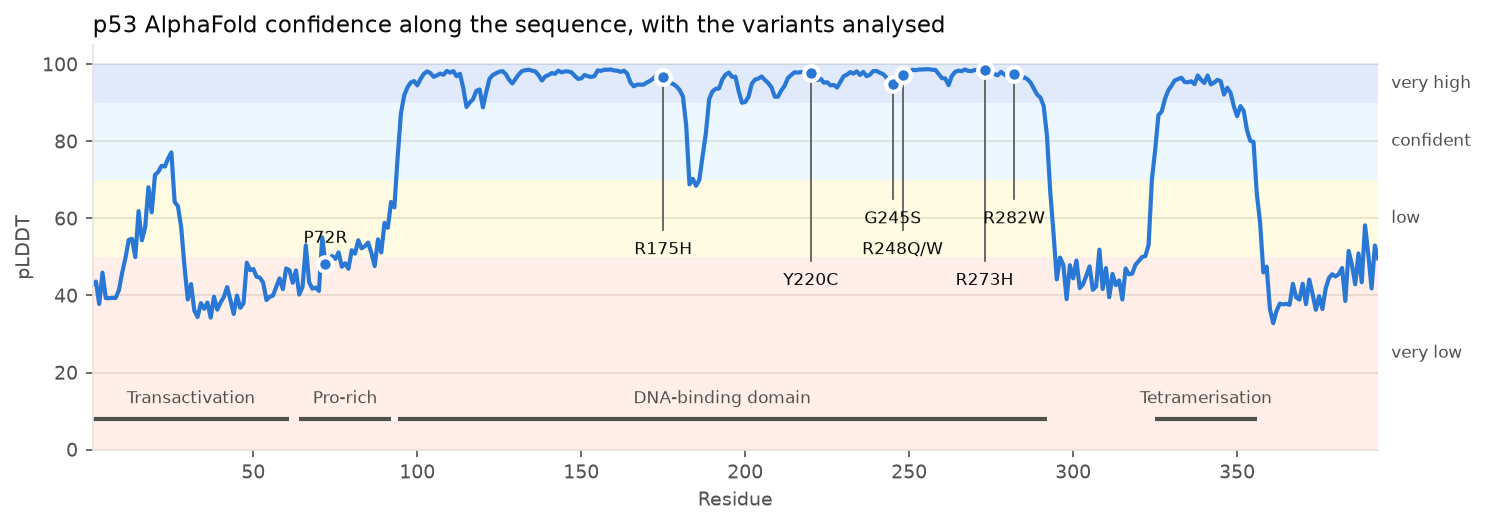

In [3]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = "#2a78d6"  # single series: categorical slot 1
BANDS = [(90, 100, "#0053D6", "very high"), (70, 90, "#65CBF3", "confident"),
         (50, 70, "#FFDB13", "low"), (0, 50, "#FF7D45", "very low")]

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

structure = results[1].structures[0]  # R175H; all variants share the p53 model
plddt = AlphaFoldClient.residue_plddt(Path(structure.structure_path))
hotspots = {r.vcf_id: r.structures[0].residue for r in results if r.structures}

fig, ax = plt.subplots(figsize=(10, 3.6), dpi=150)
for lo, hi, colour, name in BANDS:
    ax.axhspan(lo, hi, color=colour, alpha=0.12, linewidth=0)
    ax.text(max(plddt) + 4, (lo + hi) / 2, name, va="center", fontsize=8, color=MUTED)
ax.plot(list(plddt), list(plddt.values()), color=SERIES, linewidth=2)

# Group variants sharing a residue (R248Q/W), then label below the curve on
# three staggered rows with leader lines: the DBD hotspots are too close for inline labels.
by_residue = {}
for label, residue in hotspots.items():
    by_residue.setdefault(residue, []).append(label)
rows = [62, 54, 46]  # below the DBD curve, which never dips under ~68
for i, (residue, labels) in enumerate(sorted(by_residue.items())):
    y = plddt[residue]
    name = labels[0] if len(labels) == 1 else labels[0][:-1] + "/".join(lab[-1] for lab in labels)
    ax.plot(residue, y, "o", markersize=7, color=SERIES, markeredgecolor="white",
            markeredgewidth=2, zorder=3)
    if y < 70:  # outside the folded domain: room to label inline
        ax.annotate(name, (residue, y), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
        continue
    ly = rows[i % len(rows)]
    ax.plot([residue, residue], [ly + 3, y - 2], color=MUTED, linewidth=0.8, zorder=2)
    ax.text(residue, ly, name, ha="center", va="top", fontsize=8, color=INK)

# Domain architecture (UniProt P04637 annotations, approximate boundaries)
for start, end, name in [(1, 61, "Transactivation"), (64, 92, "Pro-rich"),
                         (94, 292, "DNA-binding domain"), (325, 356, "Tetramerisation")]:
    ax.plot([start, end], [8, 8], color=MUTED, linewidth=2, solid_capstyle="butt")
    ax.text((start + end) / 2, 11, name, ha="center", va="bottom", fontsize=8, color=MUTED)

ax.set_xlim(1, max(plddt))
ax.set_ylim(0, 105)
ax.set_xlabel("Residue", color=MUTED, fontsize=9)
ax.set_ylabel("pLDDT", color=MUTED, fontsize=9)
ax.set_title("p53 AlphaFold confidence along the sequence, with the variants analysed",
             loc="left", fontsize=11, color=INK)
style(ax)
fig.tight_layout()
fig.savefig(ROOT / "docs" / "img" / "tp53_plddt_profile.png", bbox_inches="tight")
plt.show()

## 3. How large are the predicted regulatory effects?

Each panel shows one representative AlphaGenome scorer (strongest signed effect over the colon tracks). The scorers have different scales, so compare variants **within** a panel, never across panels.

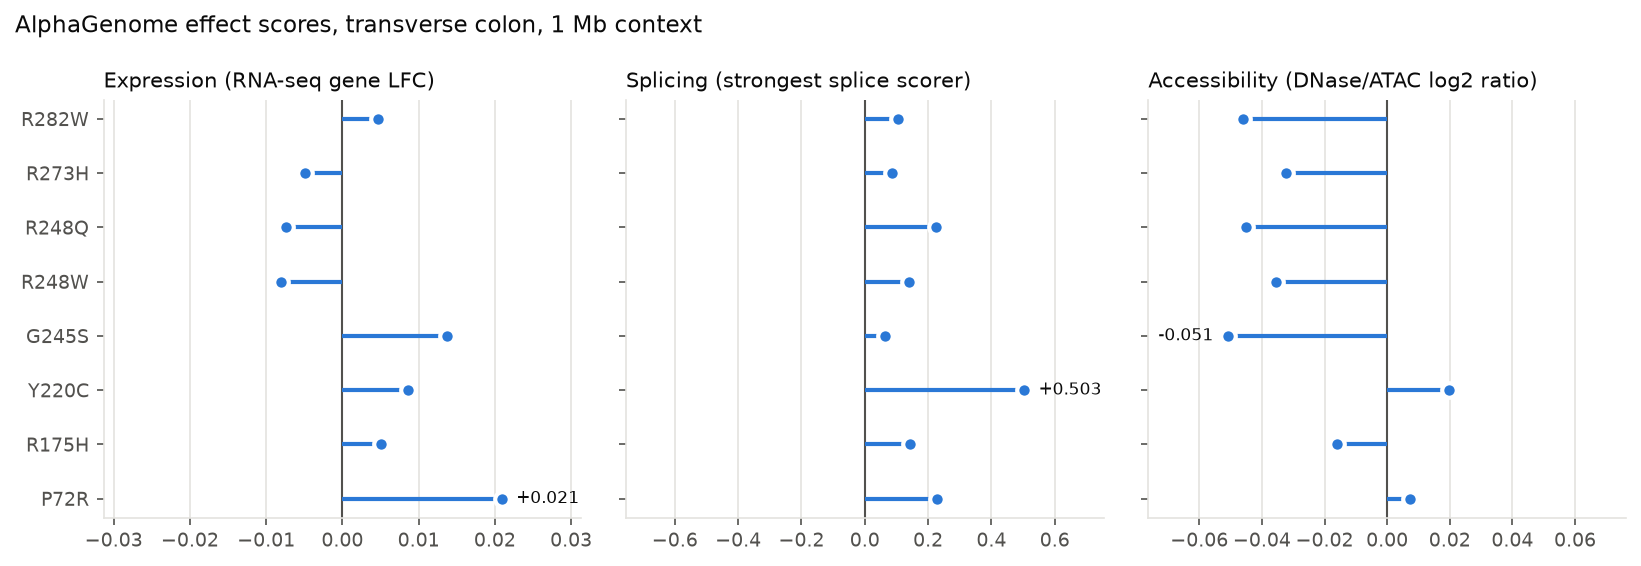

In [4]:
panels = [("rna_lfc", "Expression (RNA-seq gene LFC)"),
          ("splicing", "Splicing (strongest splice scorer)"),
          ("accessibility", "Accessibility (DNase/ATAC log2 ratio)")]
order = table.sort_values("variant")["label"].tolist()[::-1]
data = table.set_index("label").loc[order]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), dpi=150, sharey=True)
for ax, (col, title) in zip(axes, panels, strict=True):
    values = data[col]
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.hlines(range(len(values)), 0, values, color=SERIES, linewidth=2)
    ax.plot(values, range(len(values)), "o", markersize=7, color=SERIES,
            markeredgecolor="white", markeredgewidth=2)
    top = values.abs().idxmax()
    side = 1 if values[top] >= 0 else -1  # label beyond the dot, away from its stem
    ax.annotate(f"{values[top]:+.3f}", (values[top], order.index(top)), xytext=(7 * side, 0),
                textcoords="offset points", va="center", ha="left" if side > 0 else "right",
                fontsize=8, color=INK)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_yticks(range(len(order)), order)
    lim = values.abs().max() * 1.5
    ax.set_xlim(-lim, lim)
    style(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
fig.suptitle("AlphaGenome effect scores, transverse colon, 1 Mb context", x=0.01, ha="left",
             fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(ROOT / "docs" / "img" / "tp53_effects.png", bbox_inches="tight")
plt.show()

## 4. Is the hotspot's regulatory effect tissue-specific?

AlphaGenome 2 predicts for one *condition* at a time. Here R175H is compared across transverse colon, liver and blood CD14+ monocytes.

In [5]:
r175h = GenomicVariant.parse("chr17:7675088:C>T")
conditions = [COLON, "UBERON:0002107", "UBERON:0000178_CL:0001054"]
multi = pipeline.run_variant(r175h, conditions=conditions)
compare_conditions(multi.variant_scores)

condition                                                       transverse colon   liver  blood CD14-positive monocyte
output_type        scorer                                                                                             
ATAC               CenterMaskScorer(width=501, DIFF_LOG2_SUM)            -0.0021  0.0037                        0.0088
CAGE               CenterMaskScorer(width=501, DIFF_LOG2_SUM)            -0.0082  0.0056                       -0.0040
CHIP_HISTONE       CenterMaskScorer(width=2001, DIFF_LOG2_SUM)           -0.0043  0.0083                       -0.0046
CHIP_TF            CenterMaskScorer(width=501, DIFF_LOG2_SUM)             0.0091  0.0164                        0.0148
CONTACT_MAPS       ContactMapScorer()                                     0.0002  0.0003                        0.0004
DNASE              CenterMaskScorer(width=501, DIFF_LOG2_SUM)            -0.0161  0.0240                        0.0059
METHYLATION        MethylationScorer(width=1201)                         -0.0727 -0.0229                       -0.1369
RNA_SEQ            GeneMaskLFCScorer(DIFF_MEAN)                           0.0050 -0.0090                       -0.0130
                   PolyadenylationScorer()                                0.0058  0.0036                        0.0119
SC_ATAC            CenterMaskScorer(width=1201, DIFF_LOG2_SUM)            0.0013  0.0056                        0.0057
SC_GENE_EXPRESSION GeneMaskLFCScorer(DIFF_SUM)                            0.0284 -0.0257                       -0.0225
SPLICE_JUNCTIONS   SpliceJunctionScorer()                                 0.1437  0.1103                        0.1060
SPLICE_SITES       GeneMaskSplicingScorer(width=None)                     0.0014  0.0046                        0.0044
SPLICE_SITE_USAGE  GeneMaskSplicingScorer(width=None)                     0.0117  0.0072                        0.0111

## 5. Interactive 3D report

`write_report` produces a self-contained HTML page for each structure. It shows the AlphaFold model coloured by pLDDT, R175 highlighted, and the comparison table alongside. Open it in a browser:

In [6]:
html = [p for p in write_report(multi, ROOT / "results" / "notebook").parent.glob("*.html")]
print(*[p.relative_to(ROOT) for p in html], sep="\n")

results/notebook/chr17_7675088_C_T_AF-P04637-F1.html


![3D report for R175H](../docs/img/tp53_r175h_viewer.png)

## What the data say

**Structure: every hotspot sits in the folded core.** All seven hotspot residues fall in the DNA-binding domain, where AlphaFold is very confident (residue pLDDT 94.8–98.6). The P72R polymorphism lies in the disordered proline-rich region (pLDDT 48). The data fit the established view that hotspots disrupt p53's folding or DNA contacts rather than its expression.

**Regulation: predicted effects are small.** Across the hotspots, AlphaGenome's gene-level RNA-seq log fold changes stay within ±0.014. Accessibility changes stay within ±0.051. For coding missense variants that is the expected result: the model sees DNA sequence, not protein function.

**One outlier worth following up: Y220C and splicing.** Y220C's strongest splicing score (+0.50) is more than twice that of any other variant (next: P72R and R248Q at +0.23). This is a model prediction, not evidence. It is a concrete hypothesis to check against RNA-seq from Y220C carriers or a minigene assay.

**R175H looks similar across tissues.** Its splice-junction score is consistent in colon, liver and CD14+ monocytes (+0.11 to +0.14). The largest between-tissue spread is in methylation (−0.02 to −0.14).

### Caveats
* AlphaGenome 2 reports raw scores without calibrated thresholds. Compare variants within a scorer, not across scorers.
* Window size matters. A 16 kb context does not cover TP53's full gene body, and it gave different (generally smaller) splicing scores for these variants than the 1 Mb context used here.
* pLDDT is the model's confidence in the predicted structure, not a measure of the mutation's effect.